# OS Random Number Generators and Cryptographic Suitability

Input files: `urandom.bin` (Linux), `openssl.bin` (OpenSSL), and `cng.bin` (Windows CNG). Each file should contain 1 MB of random data.

## Loading the data

In [1]:
import numpy as np, pandas as pd, zlib, math, hashlib, random
import matplotlib.pyplot as plt
from scipy import stats
from collections import Counter

files = {"Linux /dev/urandom": "urandom.bin",
         "OpenSSL rand": "openssl.bin",
         "Windows CNG (.NET)": "cng.bin"}
data = {name: np.fromfile(path, dtype=np.uint8) for name, path in files.items()}
for name, d in data.items():
    print(f"{name:22s} {len(d):>9d} bytes")

/home/asus/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Linux /dev/urandom       1048576 bytes
OpenSSL rand             1048576 bytes
Windows CNG (.NET)       1048576 bytes


## Randomness analysis

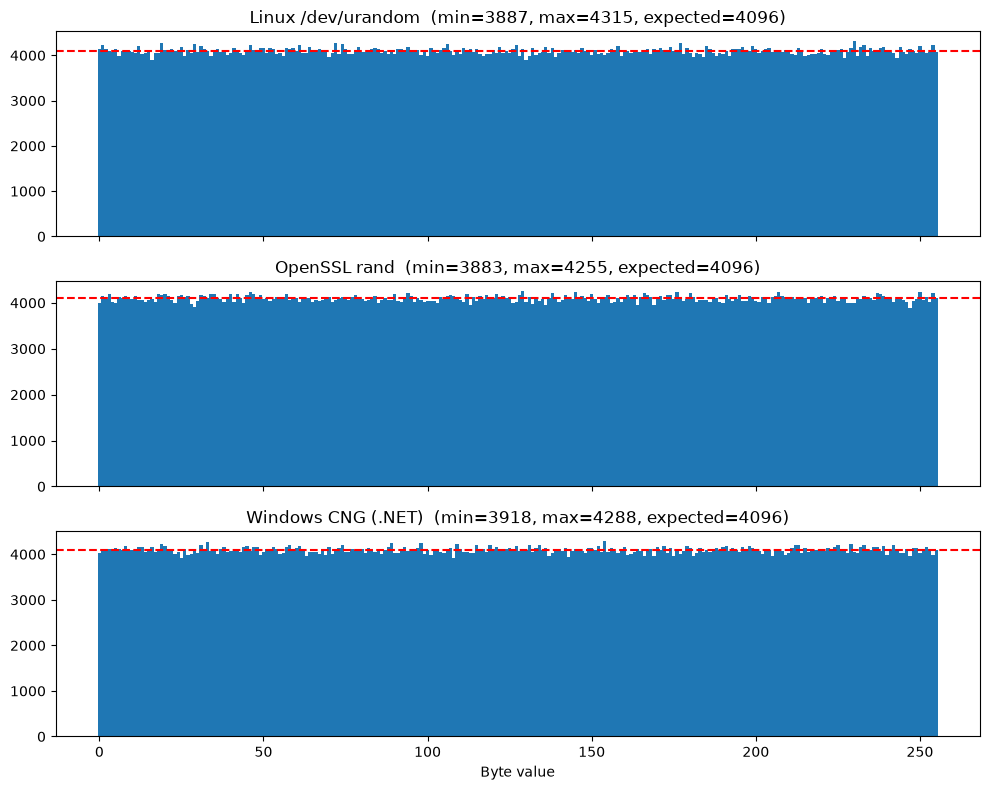

In [2]:
fig, axes = plt.subplots(len(data), 1, figsize=(10, 8), sharex=True)
for ax, (name, d) in zip(axes, data.items()):
    c = np.bincount(d, minlength=256)
    ax.bar(range(256), c, width=1.0)
    ax.axhline(len(d)/256, color="red", ls="--")
    ax.set_title(f"{name}  (min={c.min()}, max={c.max()}, expected={len(d)/256:.0f})")
axes[-1].set_xlabel("Byte value")
plt.tight_layout(); plt.show()

In [3]:
rows = []
for name, d in data.items():
    bits = np.unpackbits(d)
    per_pos = [((d >> i) & 1).mean() for i in range(8)]
    rows.append({"Source": name, "Ones": int(bits.sum()), "Zeros": int(len(bits) - bits.sum()),
                 "Ones ratio": round(bits.mean(), 5),
                 "Per-bit-position ratio (min..max)": f"{min(per_pos):.4f}..{max(per_pos):.4f}"})
pd.DataFrame(rows)

,Source,Ones,Zeros,Ones ratio,Per-bit-position ratio (min..max)
0,Linux /dev/urandom,4194938,4193670,0.50008,0.4994..0.5009
1,OpenSSL rand,4194036,4194572,0.49997,0.4988..0.5012
2,Windows CNG (.NET),4194271,4194337,0.50000,0.4997..0.5003


In [4]:
rows = []
for name, d in data.items():
    row = {"Source": name}
    for k in (2, 4, 8):
        n = (len(d) // k)
        blocks = [d[i*k:(i+1)*k].tobytes() for i in range(n)]
        c = Counter(blocks)
        repeated = sum(v - 1 for v in c.values() if v > 1)
        expected = n * n / (2 * 256**k)
        row[f"{k}-byte repeats (expected ~{expected:.1f})"] = repeated
    rows.append(row)
pd.DataFrame(rows)

,Source,2-byte repeats (expected ~2097152.0),4-byte repeats (expected ~8.0),8-byte repeats (expected ~0.0)
0,Linux /dev/urandom,458770,11,0
1,OpenSSL rand,458782,5,0
2,Windows CNG (.NET),458772,4,0


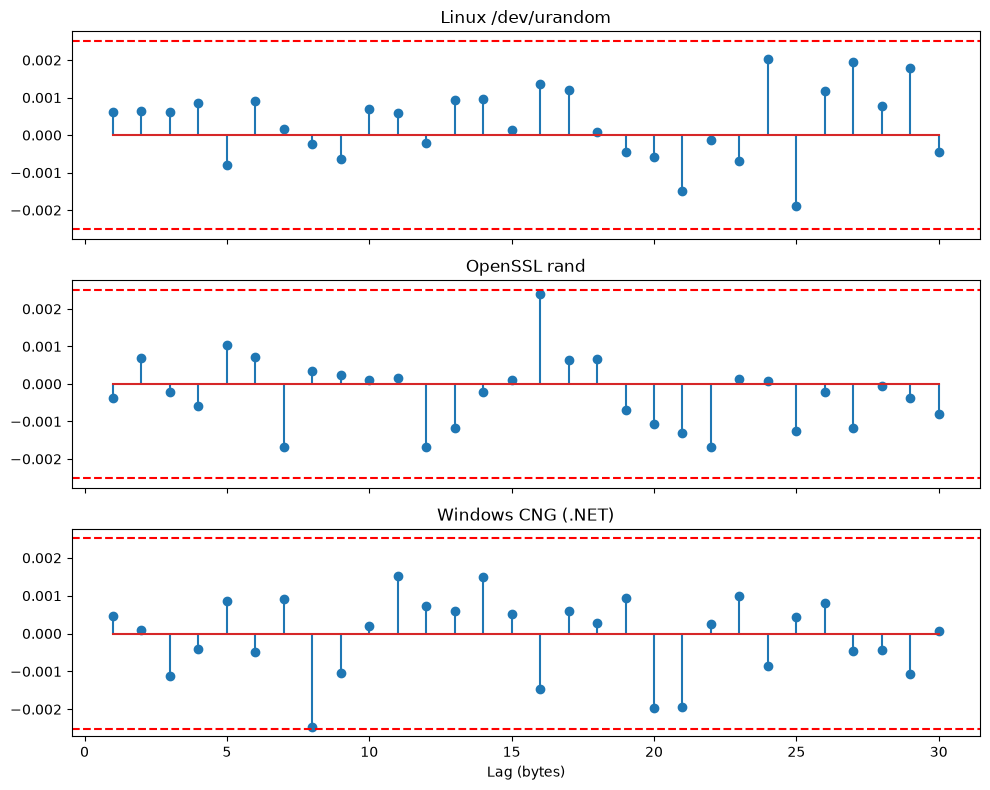

In [5]:
fig, axes = plt.subplots(len(data), 1, figsize=(10, 8), sharex=True)
for ax, (name, d) in zip(axes, data.items()):
    x = d.astype(float) - d.mean()
    lags = range(1, 31)
    ac = [np.dot(x[:-l], x[l:]) / np.dot(x, x) for l in lags]
    ax.stem(list(lags), ac)
    bound = 2.576 / math.sqrt(len(d))
    ax.axhline(bound, color="red", ls="--"); ax.axhline(-bound, color="red", ls="--")
    ax.set_title(name)
axes[-1].set_xlabel("Lag (bytes)")
plt.tight_layout(); plt.show()

## Statistical tests

In [6]:
ALPHA = 0.01

def chi_square_bytes(d):
    c = np.bincount(d, minlength=256)
    return stats.chisquare(c).pvalue

def monobit(d):
    bits = np.unpackbits(d).astype(np.int64)
    n = len(bits)
    s = abs(2 * bits.sum() - n)
    return math.erfc(s / math.sqrt(n) / math.sqrt(2))

def runs_test(d):
    bits = np.unpackbits(d)
    n = len(bits); pi = bits.mean()
    if abs(pi - 0.5) >= 2 / math.sqrt(n):
        return 0.0
    v = 1 + np.count_nonzero(bits[1:] != bits[:-1])
    return math.erfc(abs(v - 2*n*pi*(1-pi)) / (2*math.sqrt(2*n)*pi*(1-pi)))

def serial_corr_test(d, lag=1):
    x = d.astype(float)
    r = np.corrcoef(x[:-lag], x[lag:])[0, 1]
    z = r * math.sqrt(len(x) - lag)
    return 2 * (1 - stats.norm.cdf(abs(z)))

def entropy_bits_per_byte(d):
    p = np.bincount(d, minlength=256) / len(d)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def compression_ratio(d):
    return len(zlib.compress(d.tobytes(), 9)) / len(d)

def run_all(datasets):
    rows = []
    for name, d in datasets.items():
        tests = {"Chi-square (bytes)": chi_square_bytes(d),
                 "Monobit": monobit(d),
                 "Runs": runs_test(d),
                 "Serial corr. lag 1": serial_corr_test(d)}
        row = {"Source": name}
        for t, p in tests.items():
            row[t + " p"] = round(p, 4)
            row[t] = "PASS" if p >= ALPHA else "FAIL"
        row["Entropy (bits/byte)"] = round(entropy_bits_per_byte(d), 6)
        row["zlib ratio"] = round(compression_ratio(d), 4)
        rows.append(row)
    return pd.DataFrame(rows)

results = run_all(data)
results.T

,0,1,2
Source,Linux /dev/urandom,OpenSSL rand,Windows CNG (.NET)
Chi-square (bytes) p,0.0222,0.2034,0.1832
Chi-square (bytes),PASS,PASS,PASS
Monobit p,0.6615,0.8532,0.9818
Monobit,PASS,PASS,PASS
Runs p,0.7413,0.6123,0.5882
Runs,PASS,PASS,PASS
Serial corr. lag 1 p,0.5336,0.7029,0.6441
Serial corr. lag 1,PASS,PASS,PASS
Entropy (bits/byte),7.999792,7.999812,7.999811


### Interpretation of the results (fill in using your own numbers)

- A test **passes** when its p-value is at least 0.01. The p-value is the chance of seeing a result at least this extreme if the data were truly random, so a good generator will occasionally give a small p-value by chance (about 1 in 100 per test). If one test fails, rerun the generation and test once before drawing conclusions. Repeated, consistent failures are what matter.
- **Chi-square:** p between 0.01 and 0.99 means the byte frequencies are consistent with uniform.
- **Monobit and runs:** the share of 1-bits is close to 0.5, and the number of 0/1 runs is close to what random data gives.
- **Serial correlation:** values near 0 mean a byte tells you nothing about the next byte.
- **Entropy:** about 7.9998 or higher bits/byte for 1 MB of data (the maximum is 8).
- **zlib ratio:** about 1.0 or slightly above, since random data can't be compressed.
- **Repeats:** for 2-byte and 4-byte blocks, some repeats are expected by chance (see the expected value in the column header). Zero repeats would actually be suspicious.

Write 3-5 sentences here stating whether the three sources behave the same and whether any test failed.

## How operating systems generate secure random data

## Comparison and cryptographic security

### Comparison

| Aspect | Linux /dev/urandom | OpenSSL rand | Windows CNG |
|---|---|---|---|
| Underlying generator | ChaCha20-based CSPRNG | CTR-DRBG (AES-256) | AES CTR-DRBG (SP 800-90A) |
| Entropy source | Kernel entropy pool (interrupts, jitter, hardware RNG) | Seeded from the OS | Windows entropy infrastructure (timing, CPU RNG, TPM) |
| Blocking after boot | No | No | No |
| Standard | Kernel design, not a certified standard | NIST SP 800-90A design | NIST SP 800-90A, FIPS 140 validated modules |
| Result in this experiment | Fill in from the test results | Fill in from the test results | Fill in from the test results |

In [7]:
mt_bytes = np.frombuffer(random.Random(12345).randbytes(1_048_576), dtype=np.uint8)
hash_counter = b"".join(hashlib.sha256(i.to_bytes(8, "big")).digest() for i in range(32768))
hash_bytes = np.frombuffer(hash_counter, dtype=np.uint8)

weak = {"Mersenne Twister (seed 12345)": mt_bytes,
        "SHA-256(counter), public input": hash_bytes}
display(run_all(weak).T)

again = np.frombuffer(random.Random(12345).randbytes(1_048_576), dtype=np.uint8)
print("Mersenne Twister output reproduced from the seed:", np.array_equal(mt_bytes, again))

,0,1
Source,Mersenne Twister (seed 12345),"SHA-256(counter), public input"
Chi-square (bytes) p,0.3442,0.6298
Chi-square (bytes),PASS,PASS
Monobit p,0.0143,0.9983
Monobit,PASS,PASS
Runs p,0.5096,0.8689
Runs,PASS,PASS
Serial corr. lag 1 p,0.2198,0.3617
Serial corr. lag 1,PASS,PASS
Entropy (bits/byte),7.999819,7.99983


Mersenne Twister output reproduced from the seed: True


### Why passing statistical tests does not guarantee cryptographic security

- **Tests measure only statistical properties.** They check whether output *looks* uniform. Security requires that an attacker who sees any amount of output cannot predict past or future output. The demo above shows two generators that look random to the tests but are completely predictable.
- **Mersenne Twister** (used by Python's `random` and many languages) passes standard test batteries, but its full internal state can be recovered from 624 consecutive 32-bit outputs, after which every future output is known.
- **Hash of a counter with a public input** is perfectly uniform-looking, yet anyone can recompute it. Security comes from a secret seed or key, which tests cannot see.
- **A good seed matters as much as a good algorithm.** A strong algorithm seeded with a low-entropy or guessable value (a timestamp, a process ID) is predictable, and the output still passes every test. Real-world failures of this kind include weak keys from poorly seeded generators on freshly booted devices.
- **Tests only sample a finite output.** A test cannot rule out a backdoor or hidden structure that requires knowledge of a secret (as in the Dual_EC_DRBG controversy).
- **Security is defined against an adversary.** It rests on assumptions (for example, that ChaCha20 or AES behaves as a pseudorandom function), on careful design, on entropy management, and on forward secrecy and reseeding. Statistical tests are a useful sanity check that catches broken implementations, but they are necessary, not sufficient.